### 비선형 이진분류(동심원 데이터)

In [1]:
import torch
import matplotlib.pyplot as plt

#### step 1. 데이터 생성

In [2]:
n = 100
r1 = 0.3 + 0.05 * torch.randn(int(n / 2), 1)  # 0.3 주변의 값 50개
r2 = 1 + 0.05 * torch.randn(int(n / 2), 1)  # 1 주변의 값 50개
th1 = (
    2 * torch.pi * torch.rand(int(n / 2), 1) - torch.pi
)  # 각도 만들기(-파이~파이 사이 값)
th2 = 2 * torch.pi * torch.rand(int(n / 2), 1) - torch.pi
# x, y로 바꾸기. 극작표를 직교좌표로 변환
c1d = torch.hstack([r1 * torch.cos(th1), r1 * torch.sin(th1)])
c2d = torch.hstack([r2 * torch.cos(th2), r2 * torch.sin(th2)])
c1l = torch.ones(int(n / 2), 1)
c2l = torch.zeros(int(n / 2), 1)
X = torch.vstack([c1d, c2d])
Y = torch.vstack([c1l, c2l])

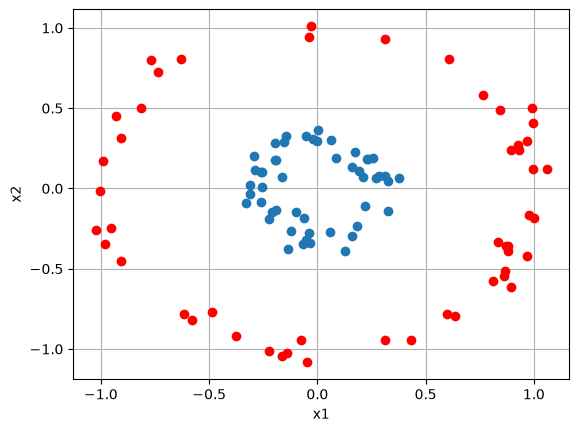

In [5]:
plt.plot(c1d[:, 0], c1d[:, 1], "o")
plt.plot(c2d[:, 0], c2d[:, 1], "ro")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid()

#### step 2. 모델 만들기

In [6]:
from torch import nn


class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(2, 100), nn.Sigmoid(), nn.Linear(100, 1), nn.Sigmoid()
        )

    def forward(self, x):
        x = self.linear(x)
        return x

In [7]:
m = MLP()

#### step 3. 모델 학습 시키기

In [9]:
from torch import optim

LR = 1e-1
EPOCH = 100
op = optim.Adam(m.parameters(), lr=LR)
cir = nn.BCELoss()
lh = []
m.train()
for ep in range(EPOCH):
    y_hat = m(X)
    loss = cir(y_hat, Y)
    op.zero_grad()
    loss.backward()
    op.step()
    lh += [loss.item()]
    print(f"epoch: {ep+1}, train loss: {loss.item():.4f}")

epoch: 1, train loss: 2.3343
epoch: 2, train loss: 0.6875
epoch: 3, train loss: 1.4550
epoch: 4, train loss: 1.2999
epoch: 5, train loss: 0.7874
epoch: 6, train loss: 0.7260
epoch: 7, train loss: 0.9769
epoch: 8, train loss: 1.0179
epoch: 9, train loss: 0.8618
epoch: 10, train loss: 0.6938
epoch: 11, train loss: 0.6731
epoch: 12, train loss: 0.7632
epoch: 13, train loss: 0.8243
epoch: 14, train loss: 0.8011
epoch: 15, train loss: 0.7262
epoch: 16, train loss: 0.6637
epoch: 17, train loss: 0.6532
epoch: 18, train loss: 0.6817
epoch: 19, train loss: 0.7095
epoch: 20, train loss: 0.7095
epoch: 21, train loss: 0.6815
epoch: 22, train loss: 0.6445
epoch: 23, train loss: 0.6206
epoch: 24, train loss: 0.6182
epoch: 25, train loss: 0.6286
epoch: 26, train loss: 0.6357
epoch: 27, train loss: 0.6295
epoch: 28, train loss: 0.6110
epoch: 29, train loss: 0.5890
epoch: 30, train loss: 0.5731
epoch: 31, train loss: 0.5665
epoch: 32, train loss: 0.5651
epoch: 33, train loss: 0.5609
epoch: 34, train lo

In [ ]:
plt.plot(range(1,EPOCH))

#### step 4. 모델 테스트

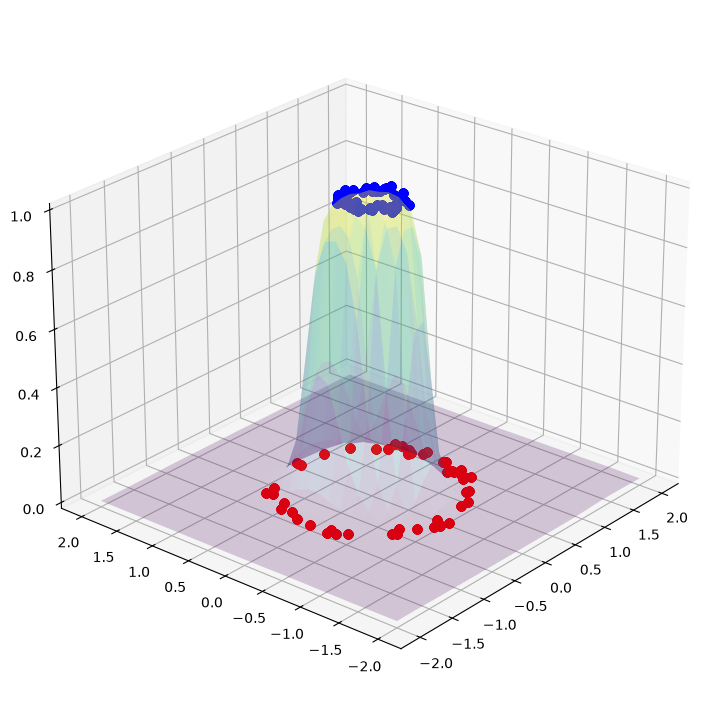

In [11]:
x1t = torch.linspace(-2, 2, 30)
x2t = torch.linspace(-2, 2, 30)
X1t, X2t = torch.meshgrid(x1t, x2t)
xt = torch.cat([X1t.unsqueeze(dim=2), X2t.unsqueeze(dim=2)], dim=2)
m.eval()
with torch.no_grad():
    y_hat = m(xt)
Y_hat = y_hat.squeeze()
plt.figure(figsize=(10, 9))
ax = plt.axes(projection="3d")
ax.view_init(elev=25, azim=-140)
ax.plot_surface(X1t, X2t, Y_hat.numpy(), cmap="viridis", alpha=0.2)
plt.plot(c1d[:, 0], c1d[:, 1], c1l, "bo")
plt.plot(c2d[:, 0], c2d[:, 1], c2l, "ro")